# Homework 3, 4

## 1. Time Series Classification Part 1: Feature Creation/Extraction

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### (a) and (b)

In [15]:
DATA_PATH = Path("AReM")

activity_folders = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

In [16]:
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [17]:
def read_dataset(file_path):
    file_path = Path(file_path)

    if file_path.parent.name == "bending2" and file_path.name == "dataset4.csv":
        data = pd.read_csv(
            file_path,
            comment="#",
            sep=r"\s+",
            header=None,
            names=column_names
        )
    else:
        data = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            usecols=range(7),
            names=column_names
        )
    data = data.apply(pd.to_numeric, errors="coerce")
    data = data.sort_values("time")

    if len(data) < 480:
        expected_time = np.arange(0, 120000, 250)

        data = (
            data.set_index("time")
                .reindex(expected_time)
                .interpolate(method="linear")
                .reset_index()
                .rename(columns={"index": "time"})
        )

    return data

In [18]:
train_files = []
test_files = []

for activity in activity_folders:
    folder_path = DATA_PATH / activity

    for file_path in folder_path.glob("dataset*.csv"):
        dataset_number = int(file_path.stem.replace("dataset", ""))

        if activity in ["bending1", "bending2"]:
            is_test = dataset_number in [1, 2]
        else:
            is_test = dataset_number in [1, 2, 3]

        file_info = {
            "activity": activity,
            "dataset": dataset_number,
            "file_path": file_path
        }

        if is_test:
            test_files.append(file_info)
        else:
            train_files.append(file_info)
            
print("Number of training instances:", len(train_files))
print("Number of test instances:", len(test_files))
print("Total:", len(train_files) + len(test_files))

Number of training instances: 69
Number of test instances: 19
Total: 88


### (c)

#### i

Include minimum, maximum, mean, median, standard deviation, variance, range, first quartile, third quartile, interquartile range, root mean square, skewness, kurtosis, and zero-crossing rate.

#### ii

In [19]:
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

def extract_features(data):
    features = {}

    for i, column in enumerate(time_series_columns, start=1):
        series = data[column]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"first_quartile{i}"] = series.quantile(0.25)
        features[f"third_quartile{i}"] = series.quantile(0.75)

    return features

In [20]:
def create_feature_dataset(file_list, set_name):
    rows = []

    for file_info in file_list:
        data = read_dataset(file_info["file_path"])
        features = extract_features(data)

        features["activity"] = file_info["activity"]
        features["dataset"] = file_info["dataset"]
        features["set"] = set_name

        rows.append(features)

    return pd.DataFrame(rows)

train_features = create_feature_dataset(train_files, "train")
test_features = create_feature_dataset(test_files, "test")

feature_dataset = pd.concat(
    [train_features, test_features],
    ignore_index=True
)

In [21]:
feature_columns = []

for i in range(1, 7):
    feature_columns.extend([
        f"min{i}",
        f"max{i}",
        f"mean{i}",
        f"median{i}",
        f"std{i}",
        f"first_quartile{i}",
        f"third_quartile{i}"
    ])

feature_dataset = feature_dataset[
    ["activity", "dataset", "set"] + feature_columns
]

print("Shape of feature dataset:", feature_dataset.shape)
feature_dataset.head()
print("Number of extracted features:", len(feature_columns))

Shape of feature dataset: (88, 45)
Number of extracted features: 42


#### iii

In [22]:
def bootstrap_std_confidence_intervals(
    data,
    n_bootstrap=10000,
    confidence_level=0.90,
    random_state=42
):
    rng = np.random.default_rng(random_state)
    values = data.to_numpy()

    n_instances, n_features = values.shape

    bootstrap_std = np.empty((n_bootstrap, n_features))

    for i in range(n_bootstrap):
        sample_indices = rng.choice(
            n_instances,
            size=n_instances,
            replace=True
        )

        bootstrap_sample = values[sample_indices]

        bootstrap_std[i] = np.std(
            bootstrap_sample,
            axis=0,
            ddof=1
        )

    alpha = 1 - confidence_level

    lower_bounds = np.quantile(
        bootstrap_std,
        alpha / 2,
        axis=0
    )

    upper_bounds = np.quantile(
        bootstrap_std,
        1 - alpha / 2,
        axis=0
    )

    original_std = data.std(ddof=1)

    results = pd.DataFrame({
        "Feature": data.columns,
        "Standard Deviation": original_std.values,
        "90% CI Lower": lower_bounds,
        "90% CI Upper": upper_bounds
    })

    return results

bootstrap_results = bootstrap_std_confidence_intervals(
    feature_dataset[feature_columns],
    n_bootstrap=10000,
    confidence_level=0.90,
    random_state=42
)
bootstrap_results.round(3)

,Feature,Standard Deviation,90% CI Lower,90% CI Upper
0,min1,9.570,8.244,10.759
1,max1,4.394,3.327,5.306
2,mean1,5.336,4.706,5.879
3,median1,5.440,4.796,5.994
4,std1,1.772,1.573,1.949
5,first_quartile1,6.154,5.569,6.639
6,third_quartile1,5.139,4.327,5.827
7,min2,0.000,0.000,0.000
8,max2,5.063,4.618,5.410
9,mean2,1.574,1.394,1.706


#### iv

I selected minimum, mean, and maximum. The minimum and maximum can describe the range and extreme behavior, and the mean represents overall level.

## 2. ISLR 3.7.4

### (a)

The training RSS of cubic regression will be less than or equal to that of linear regression. In linear model, the coefficients of \(X^2\) and \(X^3\) are zero, that means linear model is a special case of the cubic model. So whether it's a linear relationship or not, a cubic model can fit it.

### (b)

The test RSS of linear regression will be lower. Because the relationship of X and Y is linear, the cubic terms will not reduce bias. It can increase variance by fitting noise, which can lead to overfit.

### (c)

The training RSS of cubic regression will be less than or equal to that of linear regression. The reason is same as the questain (a).

### (d)

Unable to determine. The cubic model havs lower bias and higher variance. If the relationship is strongly nonlinear, the cubic model may perform better. If the relationship is slightly nonlinear, the linear model may perform better.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regressio

#### i

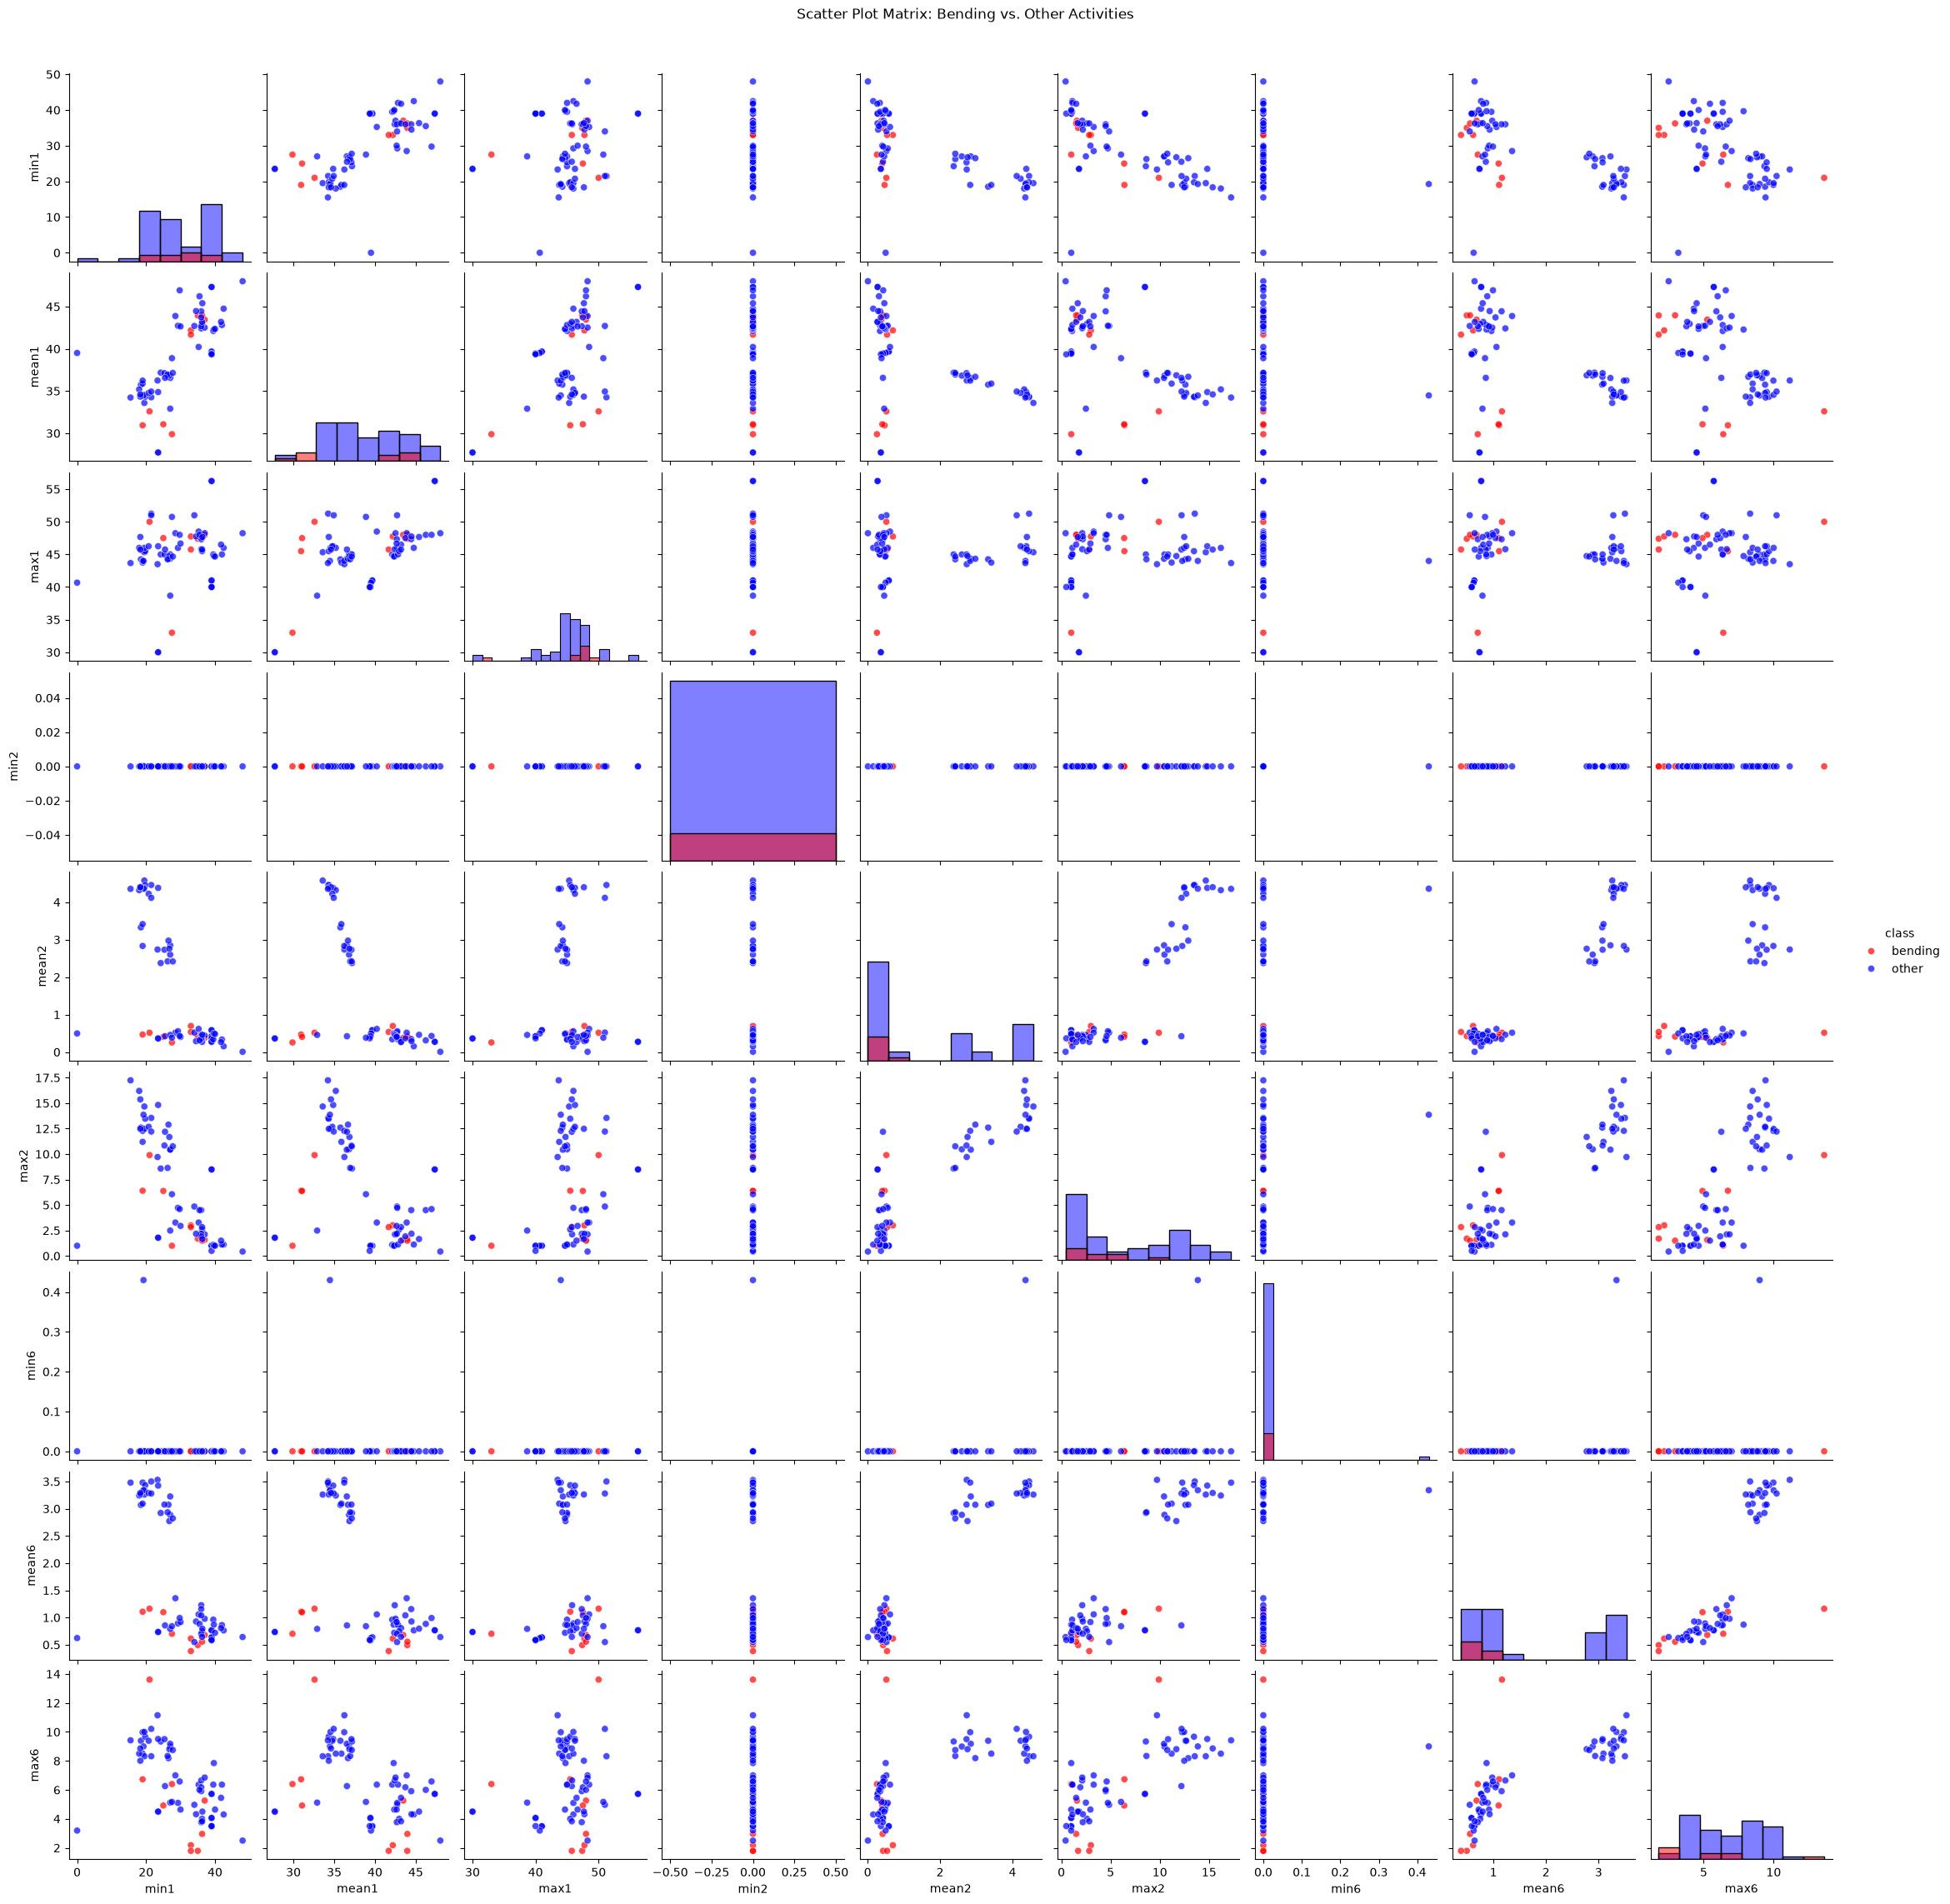

In [23]:
train_binary = train_features.copy()

train_binary["class"] = train_binary["activity"].apply(
    lambda activity: "bending"
    if activity in ["bending1", "bending2"]
    else "other"
)

selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

train_binary[selected_features + ["class"]].head()

sns.pairplot(
    train_binary[selected_features + ["class"]],
    vars=selected_features,
    hue="class",
    palette={
        "bending": "red",
        "other": "blue"
    },
    diag_kind="hist",
    plot_kws={
        "alpha": 0.7,
        "s": 35
    }
)

plt.suptitle(
    "Scatter Plot Matrix: Bending vs. Other Activities",
    y=1.02
)

plt.show()

#### ii

In [25]:
def extract_segment_features(data, num_segments=2):
    features = {}

    for series_number, column in enumerate(time_series_columns, start=1):
        segments = np.array_split(data[column].to_numpy(), num_segments)

        for segment_number, segment in enumerate(segments, start=1):
            features[f"min{series_number}_{segment_number}"] = np.min(segment)
            features[f"mean{series_number}_{segment_number}"] = np.mean(segment)
            features[f"max{series_number}_{segment_number}"] = np.max(segment)

    return features

In [33]:
rows = []

for file_info in train_files:
    data = read_dataset(file_info["file_path"])

    features = extract_segment_features(
        data,
        num_segments=2
    )

    features["activity"] = file_info["activity"]

    if file_info["activity"] in ["bending1", "bending2"]:
        features["class"] = "bending"
    else:
        features["class"] = "other"

    rows.append(features)

train_features_2_segments = pd.DataFrame(rows)

print("Shape:", train_features_2_segments.shape)
train_features_2_segments.head()

Shape: (69, 38)


,min1_1,mean1_1,max1_1,min1_2,mean1_2,max1_2,min2_1,mean2_1,max2_1,min2_2,...,mean5_2,max5_2,min6_1,mean6_1,max6_1,min6_2,mean6_2,max6_2,activity,class
0,36.50,44.057167,46.50,35.00,43.851833,47.40,0.0,0.381042,1.50,0.0,...,34.883375,38.25,0.0,0.598250,1.79,0.0,0.388333,1.50,bending1,bending
1,33.75,43.278875,47.75,33.00,41.080750,46.00,0.0,0.673292,3.00,0.0,...,30.965708,38.50,0.0,0.640958,1.53,0.0,0.586083,2.18,bending1,bending
2,33.00,41.621208,45.75,39.25,41.734917,43.67,0.0,0.623083,2.83,0.0,...,29.635833,36.00,0.0,0.419083,1.79,0.0,0.347500,1.50,bending1,bending
3,39.00,44.117042,48.00,37.00,42.792875,46.50,0.0,0.250042,1.30,0.0,...,22.850875,26.00,0.0,0.815417,5.26,0.0,0.543875,4.06,bending1,bending
4,36.67,43.486208,45.00,36.25,44.452042,48.00,0.0,0.378667,1.30,0.0,...,21.882042,26.00,0.0,0.524875,2.28,0.0,0.585750,2.96,bending1,bending


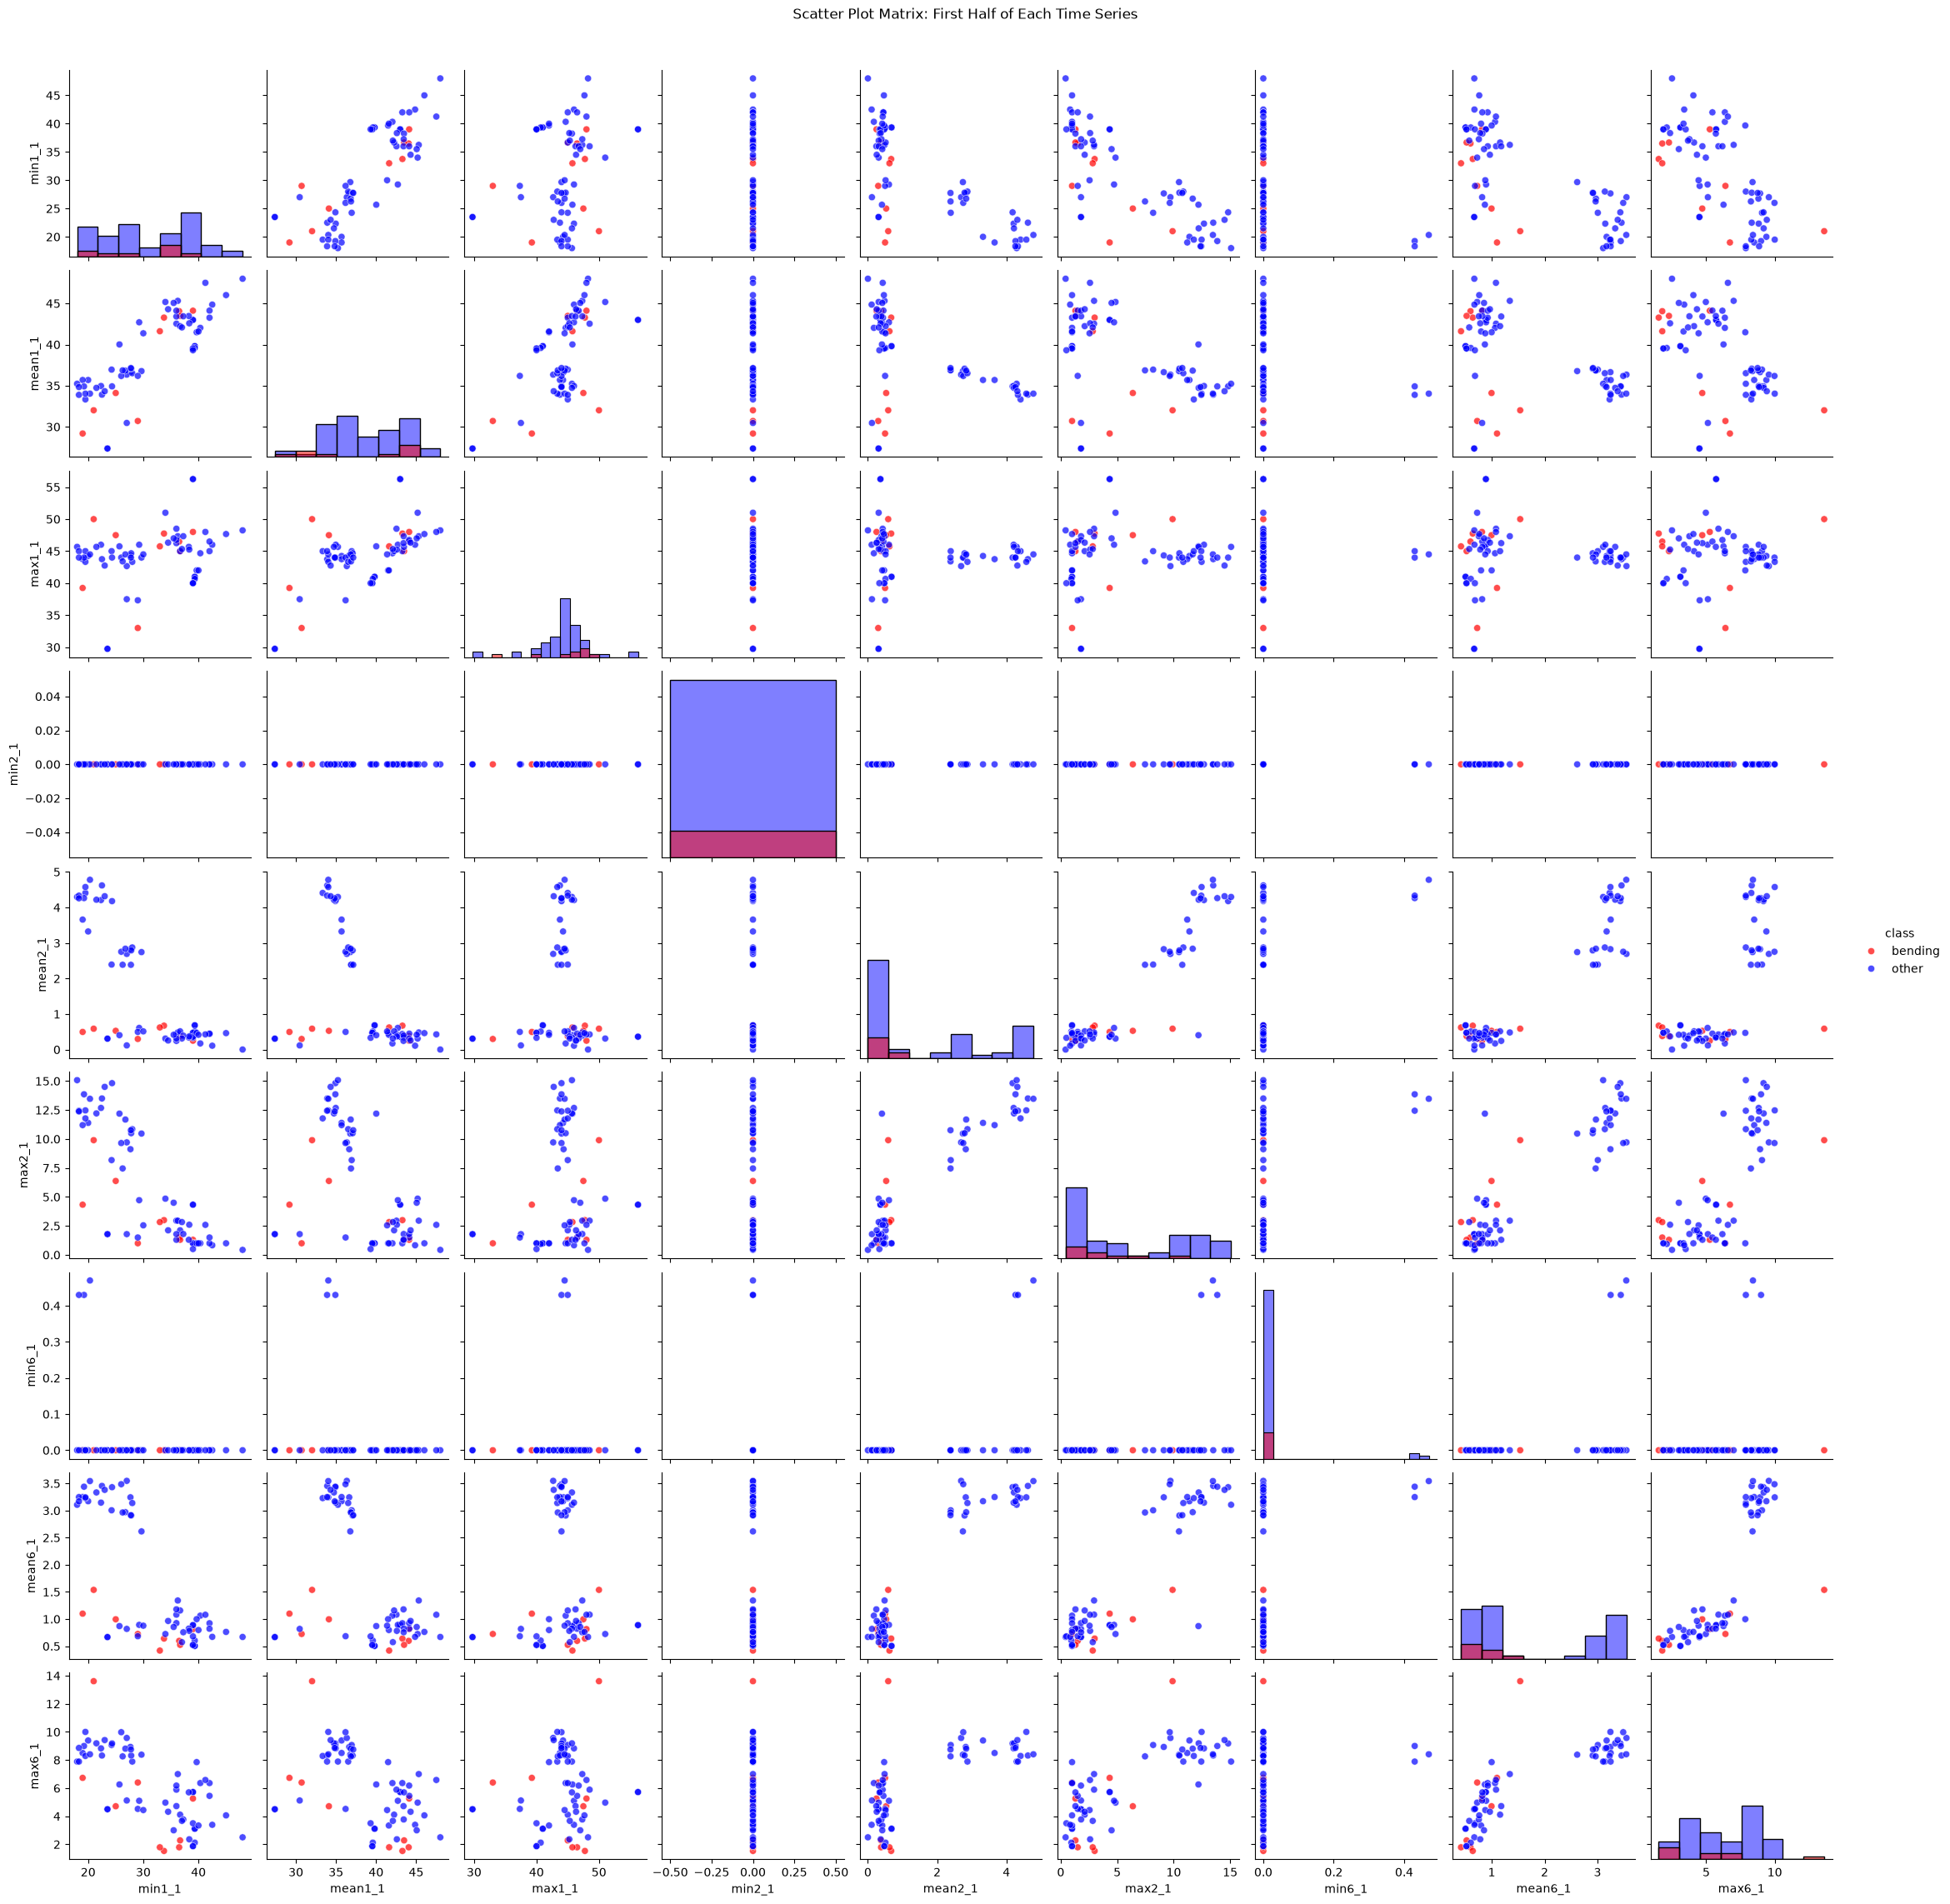

In [34]:
segment_1_features = [
    "min1_1", "mean1_1", "max1_1",
    "min2_1", "mean2_1", "max2_1",
    "min6_1", "mean6_1", "max6_1"
]

sns.pairplot(
    train_features_2_segments[segment_1_features + ["class"]],
    vars=segment_1_features,
    hue="class",
    palette={
        "bending": "red",
        "other": "blue"
    },
    diag_kind="hist",
    plot_kws={
        "alpha": 0.7,
        "s": 35
    }
)

plt.suptitle(
    "Scatter Plot Matrix: First Half of Each Time Series",
    y=1.02
)

plt.show()

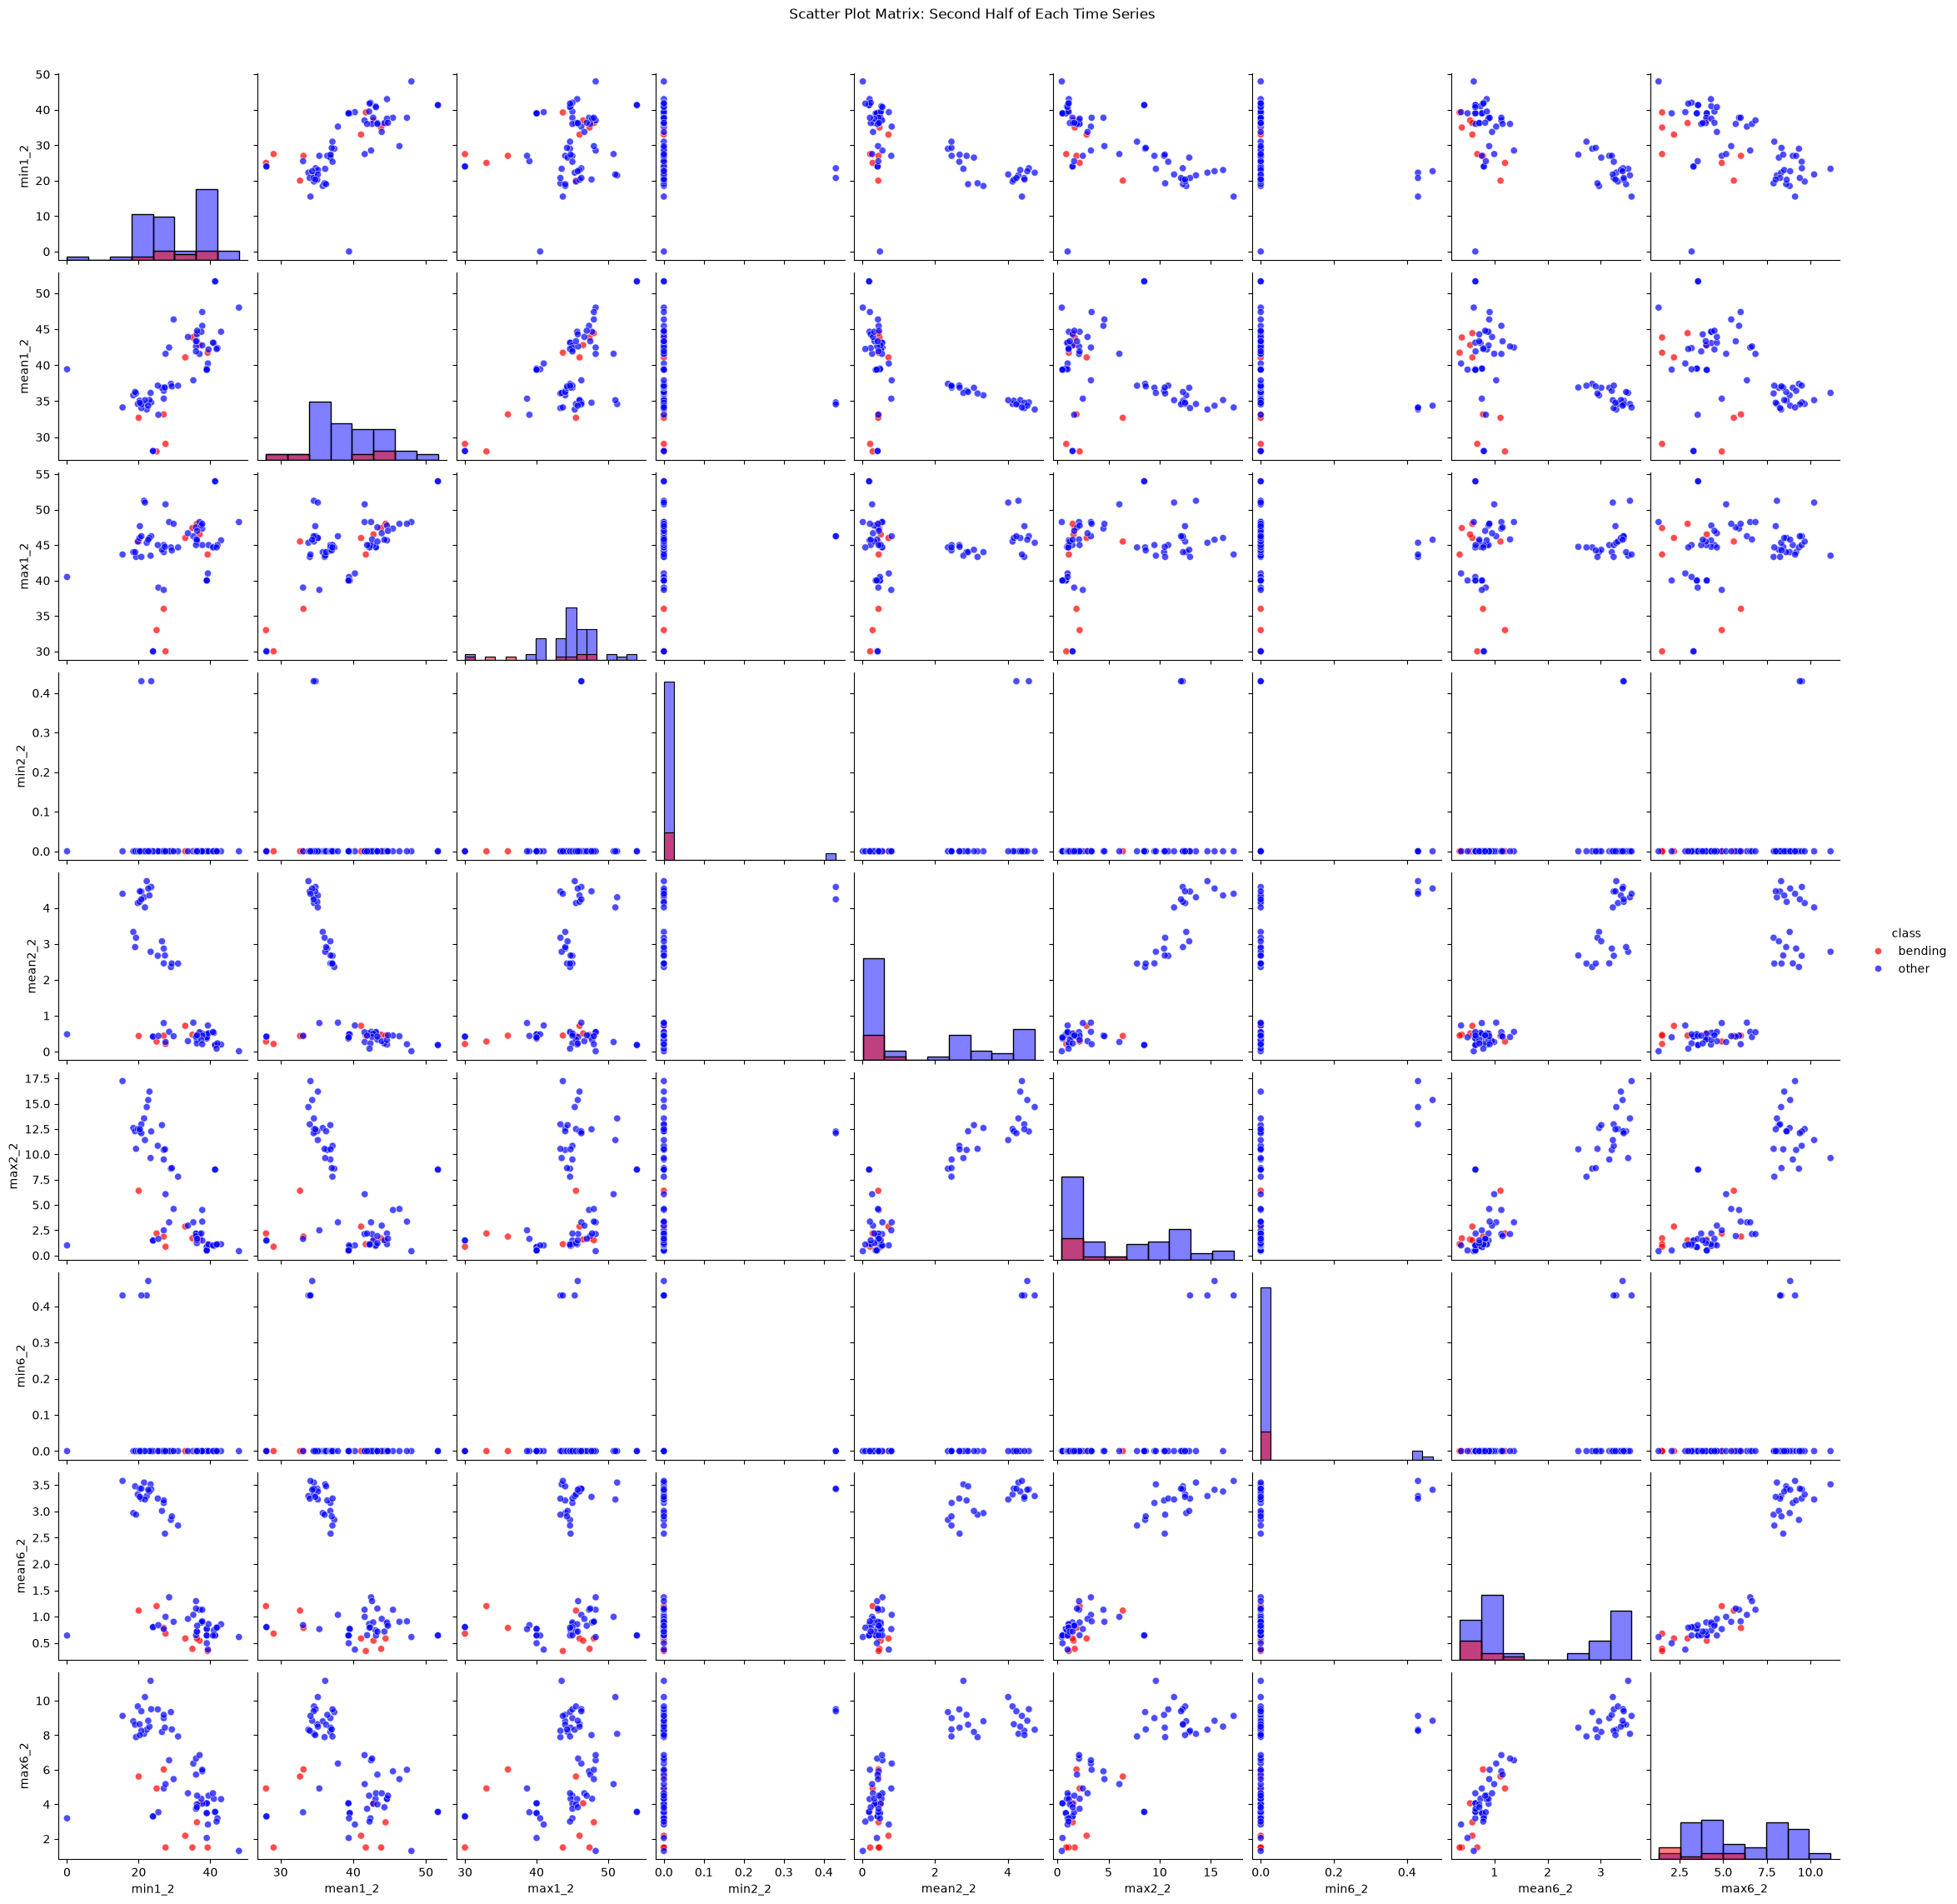

In [35]:
segment_2_features = [
    "min1_2", "mean1_2", "max1_2",
    "min2_2", "mean2_2", "max2_2",
    "min6_2", "mean6_2", "max6_2"
]

sns.pairplot(
    train_features_2_segments[segment_2_features + ["class"]],
    vars=segment_2_features,
    hue="class",
    palette={
        "bending": "red",
        "other": "blue"
    },
    diag_kind="hist",
    plot_kws={
        "alpha": 0.7,
        "s": 35
    }
)

plt.suptitle(
    "Scatter Plot Matrix: Second Half of Each Time Series",
    y=1.02
)

plt.show()

Local differences are more pronounced

#### iii

In [36]:
def extract_all_segment_features(data, num_segments):
    features = {}

    for series_number, column in enumerate(time_series_columns, start=1):
        segments = np.array_split(
            data[column].to_numpy(),
            num_segments
        )

        for segment_number, segment in enumerate(segments, start=1):
            prefix = f"{series_number}_{segment_number}"

            features[f"min{prefix}"] = np.min(segment)
            features[f"max{prefix}"] = np.max(segment)
            features[f"mean{prefix}"] = np.mean(segment)
            features[f"median{prefix}"] = np.median(segment)
            features[f"std{prefix}"] = np.std(segment, ddof=1)
            features[f"first_quartile{prefix}"] = np.quantile(
                segment,
                0.25
            )
            features[f"third_quartile{prefix}"] = np.quantile(
                segment,
                0.75
            )

    return features

In [37]:
def create_segmented_feature_dataset(file_list, num_segments):
    rows = []

    for file_info in file_list:
        data = read_dataset(file_info["file_path"])

        features = extract_all_segment_features(
            data,
            num_segments
        )

        features["activity"] = file_info["activity"]

        if file_info["activity"] in ["bending1", "bending2"]:
            features["label"] = 1
        else:
            features["label"] = 0

        rows.append(features)

    return pd.DataFrame(rows)

In [38]:
features_l1 = create_segmented_feature_dataset(
    train_files,
    num_segments=1
)

print("Shape for l = 1:", features_l1.shape)
features_l1.head()

Shape for l = 1: (69, 44)


,min1_1,max1_1,mean1_1,median1_1,std1_1,first_quartile1_1,third_quartile1_1,min2_1,max2_1,mean2_1,...,third_quartile5_1,min6_1,max6_1,mean6_1,median6_1,std6_1,first_quartile6_1,third_quartile6_1,activity,label
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,1
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,1
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,1
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,1
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,1


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFECV

In [42]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

l =  1, p =   3, CV Accuracy = 1.0000
l =  2, p =  10, CV Accuracy = 0.9429
l =  3, p =  10, CV Accuracy = 0.9429
l =  4, p =  12, CV Accuracy = 0.9571
l =  5, p =   1, CV Accuracy = 0.9571
l =  6, p =   7, CV Accuracy = 0.9714
l =  7, p =   1, CV Accuracy = 0.9418
l =  8, p = 222, CV Accuracy = 0.9429
l =  9, p = 175, CV Accuracy = 0.9571
l = 10, p =   4, CV Accuracy = 0.9714
l = 11, p =  12, CV Accuracy = 0.9571
l = 12, p =   4, CV Accuracy = 0.9714
l = 13, p =   6, CV Accuracy = 0.9571
l = 14, p =   1, CV Accuracy = 0.9429
l = 15, p =   6, CV Accuracy = 0.9571
l = 16, p = 269, CV Accuracy = 0.9429
l = 17, p =  14, CV Accuracy = 0.9571
l = 18, p =   1, CV Accuracy = 0.9571
l = 19, p =   3, CV Accuracy = 0.9571
l = 20, p =   8, CV Accuracy = 0.9429
Best l: 1
Best p: 3
Best cross-validation accuracy: 1.0


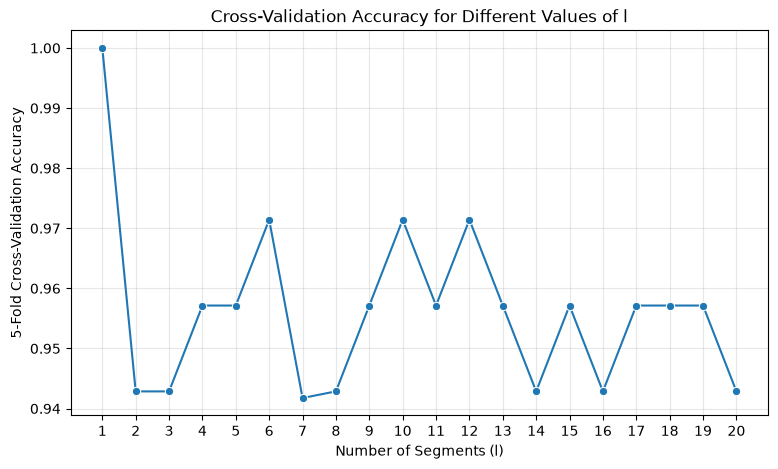

In [43]:
cv_results = []
rfecv_models = {}

for l in range(1, 21):
    segmented_data = create_segmented_feature_dataset(
        train_files,
        num_segments=l
    )

    X = segmented_data.drop(
        columns=["activity", "label"]
    )

    y = segmented_data["label"]

    logistic_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "logistic",
            LogisticRegression(
                C=1e6,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    # Use a larger elimination step when the number of features is large
    elimination_step = max(1, X.shape[1] // 50)

    selector = RFECV(
        estimator=logistic_pipeline,
        step=elimination_step,
        cv=stratified_cv,
        scoring="accuracy",
        min_features_to_select=1,
        n_jobs=-1,
        importance_getter="named_steps.logistic.coef_"
    )

    selector.fit(X, y)

    best_cv_accuracy = np.max(
        selector.cv_results_["mean_test_score"]
    )

    cv_results.append({
        "l": l,
        "p": selector.n_features_,
        "CV Accuracy": best_cv_accuracy
    })

    rfecv_models[l] = {
        "selector": selector,
        "feature_names": X.columns
    }

    print(
        f"l = {l:2d}, "
        f"p = {selector.n_features_:3d}, "
        f"CV Accuracy = {best_cv_accuracy:.4f}"
    )

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

best_result = cv_results_df.loc[
    cv_results_df["CV Accuracy"].idxmax()
]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_cv_accuracy = best_result["CV Accuracy"]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best cross-validation accuracy:", round(best_cv_accuracy, 4))

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=cv_results_df,
    x="l",
    y="CV Accuracy",
    marker="o"
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("5-Fold Cross-Validation Accuracy")
plt.title("Cross-Validation Accuracy for Different Values of l")
plt.grid(alpha=0.3)

plt.show()

#### iv

In [44]:
best_train_data = create_segmented_feature_dataset(
    train_files,
    num_segments=best_l
)

X_train_best = best_train_data.drop(
    columns=["activity", "label"]
)

y_train_best = best_train_data["label"]

best_selector = rfecv_models[best_l]["selector"]

selected_feature_names = X_train_best.columns[
    best_selector.support_
].tolist()

print("Best l:", best_l)
print("Number of selected features:", len(selected_feature_names))
print("Selected features:")
print(selected_feature_names)

Best l: 1
Number of selected features: 3
Selected features:
['min5_1', 'max5_1', 'mean5_1']


In [45]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [46]:
y_train_pred = best_selector.predict(X_train_best)

y_train_probability = best_selector.predict_proba(
    X_train_best
)[:, 1]

train_confusion_matrix = confusion_matrix(
    y_train_best,
    y_train_pred
)

print("Training Confusion Matrix:")
print(train_confusion_matrix)

Training Confusion Matrix:
[[60  0]
 [ 0  9]]


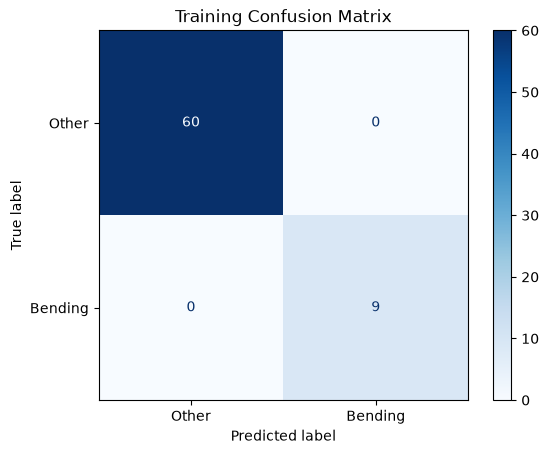

In [47]:
display = ConfusionMatrixDisplay(
    confusion_matrix=train_confusion_matrix,
    display_labels=["Other", "Bending"]
)

display.plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

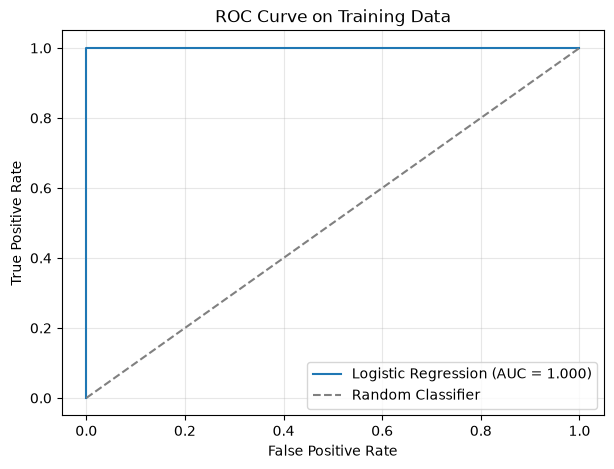

Training AUC: 1.0


In [48]:
train_auc = roc_auc_score(
    y_train_best,
    y_train_probability
)

fpr, tpr, thresholds = roc_curve(
    y_train_best,
    y_train_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {train_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Training Data")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print("Training AUC:", round(train_auc, 4))

In [49]:
import statsmodels.api as sm

selected_scaler = StandardScaler()

X_train_selected_scaled = selected_scaler.fit_transform(
    X_train_best[selected_feature_names]
)

X_train_statsmodels = pd.DataFrame(
    X_train_selected_scaled,
    columns=selected_feature_names,
    index=X_train_best.index
)

X_train_statsmodels = sm.add_constant(
    X_train_statsmodels
)

logit_model = sm.Logit(
    y_train_best,
    X_train_statsmodels
)

logit_result = logit_model.fit(
    method="lbfgs",
    maxiter=5000,
    disp=False
)

logit_result.summary()

parameter_results = pd.DataFrame({
    "Coefficient": logit_result.params,
    "p-value": logit_result.pvalues
})

parameter_results.round(6)

,Coefficient,p-value
const,-109.373209,0.967915
min5_1,119.407255,0.930543
max5_1,89.523174,0.925883
mean5_1,-44.367682,0.985624


#### v

In [50]:
best_test_data = create_segmented_feature_dataset(
    test_files,
    num_segments=best_l
)

X_test_best = best_test_data.drop(
    columns=["activity", "label"]
)

y_test_best = best_test_data["label"]

print("Test data shape:", X_test_best.shape)

print(
    "Training and test features match:",
    list(X_train_best.columns) == list(X_test_best.columns)
)

Test data shape: (19, 42)
Training and test features match: True


Cross-validation accuracy: 1.0
Test accuracy: 0.9474


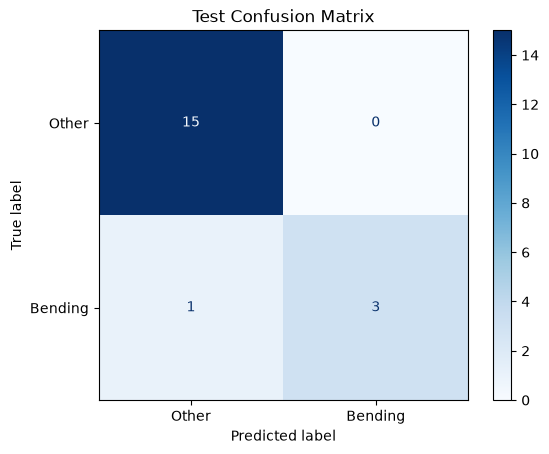

In [51]:
from sklearn.metrics import accuracy_score

y_test_pred = best_selector.predict(
    X_test_best
)

y_test_probability = best_selector.predict_proba(
    X_test_best
)[:, 1]

test_accuracy = accuracy_score(
    y_test_best,
    y_test_pred
)

print(
    "Cross-validation accuracy:",
    round(best_cv_accuracy, 4)
)

print(
    "Test accuracy:",
    round(test_accuracy, 4)
)

test_confusion_matrix = confusion_matrix(
    y_test_best,
    y_test_pred
)

display = ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=["Other", "Bending"]
)

display.plot(cmap="Blues")

plt.title("Test Confusion Matrix")
plt.show()

#### vi

In [52]:
train_accuracy = accuracy_score(
    y_train_best,
    y_train_pred
)

maximum_coefficient = np.abs(
    logit_result.params
).max()

converged = logit_result.mle_retvals.get(
    "converged",
    None
)

print("Training accuracy:", round(train_accuracy, 4))
print("Training AUC:", round(train_auc, 4))
print("Largest absolute coefficient:", round(maximum_coefficient, 4))
print("Statsmodels converged:", converged)

Training accuracy: 1.0
Training AUC: 1.0
Largest absolute coefficient: 119.4073
Statsmodels converged: True


In [53]:
statsmodels_probabilities = logit_result.predict(
    X_train_statsmodels
)

extreme_probabilities = np.sum(
    (statsmodels_probabilities < 0.001) |
    (statsmodels_probabilities > 0.999)
)

print(
    "Number of probabilities below 0.001 or above 0.999:",
    extreme_probabilities
)

print(
    "Total training observations:",
    len(statsmodels_probabilities)
)

Number of probabilities below 0.001 or above 0.999: 69
Total training observations: 69


#### vii

In [55]:
class_counts = y_train_best.value_counts().sort_index()
class_counts.index = ["Other", "Bending"]
print(class_counts)

Other      60
Bending     9
Name: count, dtype: int64


In [56]:
X_case_control = X_train_best[
    selected_feature_names
].copy()

case_control_scaler = StandardScaler()

X_case_control_scaled = case_control_scaler.fit_transform(
    X_case_control
)
rng = np.random.default_rng(42)

other_indices = np.where(
    y_train_best.to_numpy() == 0
)[0]

bending_indices = np.where(
    y_train_best.to_numpy() == 1
)[0]

sampled_bending_indices = rng.choice(
    bending_indices,
    size=len(other_indices),
    replace=True
)

balanced_indices = np.concatenate([
    other_indices,
    sampled_bending_indices
])

rng.shuffle(balanced_indices)

X_balanced = X_case_control_scaled[
    balanced_indices
]

y_balanced = y_train_best.to_numpy()[
    balanced_indices
]

print(
    "Balanced class counts:",
    np.bincount(y_balanced)
)

Balanced class counts: [60 60]


In [57]:
case_control_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=5000,
    random_state=42
)

case_control_model.fit(
    X_balanced,
    y_balanced
)

original_prevalence = y_train_best.mean()
sample_prevalence = y_balanced.mean()

intercept_adjustment = np.log(
    original_prevalence /
    (1 - original_prevalence)
) - np.log(
    sample_prevalence /
    (1 - sample_prevalence)
)

adjusted_intercept = (
    case_control_model.intercept_[0]
    + intercept_adjustment
)

print(
    "Original case-control intercept:",
    case_control_model.intercept_[0]
)

print(
    "Intercept adjustment:",
    intercept_adjustment
)

print(
    "Adjusted intercept:",
    adjusted_intercept
)

Original case-control intercept: -64.79210950639552
Intercept adjustment: -1.8971199848858813
Adjusted intercept: -66.6892294912814


In [58]:
from scipy.special import expit

case_control_log_odds = (
    X_case_control_scaled
    @ case_control_model.coef_[0]
    + adjusted_intercept
)

case_control_probability = expit(
    case_control_log_odds
)

case_control_prediction = (
    case_control_probability >= 0.5
).astype(int)

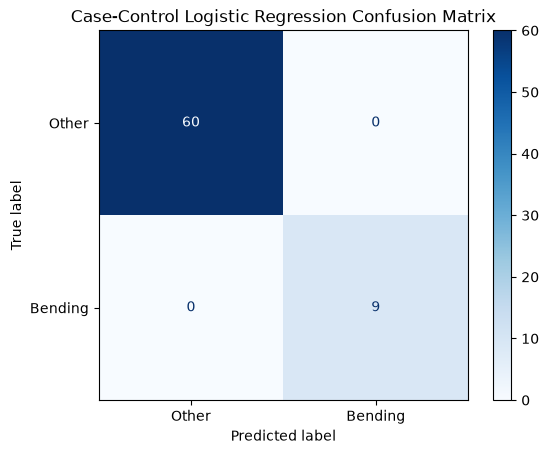

[[60  0]
 [ 0  9]]


In [59]:
case_control_confusion = confusion_matrix(
    y_train_best,
    case_control_prediction
)

display = ConfusionMatrixDisplay(
    confusion_matrix=case_control_confusion,
    display_labels=["Other", "Bending"]
)

display.plot(cmap="Blues")

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

print(case_control_confusion)

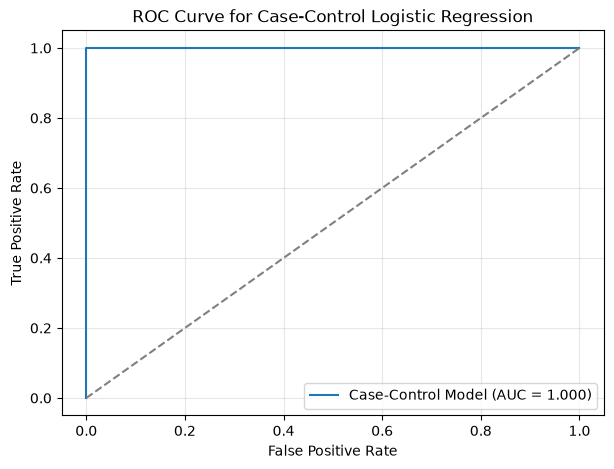

Case-control AUC: 1.0


In [60]:
case_control_auc = roc_auc_score(
    y_train_best,
    case_control_probability
)

case_fpr, case_tpr, _ = roc_curve(
    y_train_best,
    case_control_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    case_fpr,
    case_tpr,
    label=f"Case-Control Model (AUC = {case_control_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Case-Control Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

print(
    "Case-control AUC:",
    round(case_control_auc, 4)
)

### (b) Binary Classification Using L1-Penalized Logistic Regression

#### i

In [63]:
C_values = np.logspace(
    -4,
    4,
    20
)

C_values

l1_results = []
l1_models = {}

for l in range(1, 21):
    # Generate features for the current value of l
    segmented_data = create_segmented_feature_dataset(
        train_files,
        num_segments=l
    )

    X = segmented_data.drop(
        columns=["activity", "label"]
    )

    y = segmented_data["label"]

    # L1-penalized logistic regression
    l1_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "logistic",
            LogisticRegression(
                l1_ratio=1,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    parameter_grid = {
        "logistic__C": C_values
    }

    grid_search = GridSearchCV(
        estimator=l1_pipeline,
        param_grid=parameter_grid,
        cv=stratified_cv,
        scoring="accuracy",
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X, y)

    best_C_for_l = grid_search.best_params_[
        "logistic__C"
    ]

    best_accuracy_for_l = grid_search.best_score_

    best_coefficients = grid_search.best_estimator_[
        "logistic"
    ].coef_[0]

    number_nonzero = np.count_nonzero(
        best_coefficients
    )

    l1_results.append({
        "l": l,
        "C": best_C_for_l,
        "lambda": 1 / best_C_for_l,
        "Nonzero Features": number_nonzero,
        "CV Accuracy": best_accuracy_for_l
    })

    l1_models[l] = {
        "model": grid_search.best_estimator_,
        "feature_names": X.columns.tolist()
    }

    print(
        f"l = {l:2d}, "
        f"C = {best_C_for_l:.6f}, "
        f"nonzero features = {number_nonzero:3d}, "
        f"CV accuracy = {best_accuracy_for_l:.4f}"
    )

l1_results_df = pd.DataFrame(
    l1_results
)

l1_results_df

l =  1, C = 3792.690191, nonzero features =  28, CV accuracy = 0.9857
l =  2, C = 11.288379, nonzero features =  11, CV accuracy = 0.9714
l =  3, C = 0.233572, nonzero features =   5, CV accuracy = 0.9571
l =  4, C = 1438.449888, nonzero features =  52, CV accuracy = 0.9571
l =  5, C = 29.763514, nonzero features =  18, CV accuracy = 0.9418
l =  6, C = 11.288379, nonzero features =  18, CV accuracy = 0.9571
l =  7, C = 29.763514, nonzero features =  18, CV accuracy = 0.9560
l =  8, C = 78.475997, nonzero features =  26, CV accuracy = 0.9429
l =  9, C = 10000.000000, nonzero features = 140, CV accuracy = 0.9571
l = 10, C = 78.475997, nonzero features =  29, CV accuracy = 0.9714
l = 11, C = 1.623777, nonzero features =   8, CV accuracy = 0.9571
l = 12, C = 0.615848, nonzero features =   7, CV accuracy = 0.9714
l = 13, C = 0.615848, nonzero features =  10, CV accuracy = 0.9571
l = 14, C = 1.623777, nonzero features =  12, CV accuracy = 0.9571
l = 15, C = 545.559478, nonzero features =  97

,l,C,lambda,Nonzero Features,CV Accuracy
0,1,3792.690191,0.000264,28,0.985714
1,2,11.288379,0.088587,11,0.971429
2,3,0.233572,4.281332,5,0.957143
3,4,1438.449888,0.000695,52,0.957143
4,5,29.763514,0.033598,18,0.941758
5,6,11.288379,0.088587,18,0.957143
6,7,29.763514,0.033598,18,0.956044
7,8,78.475997,0.012743,26,0.942857
8,9,10000.000000,0.000100,140,0.957143
9,10,78.475997,0.012743,29,0.971429


In [64]:
best_l1_result = l1_results_df.loc[
    l1_results_df["CV Accuracy"].idxmax()
]

best_l_l1 = int(
    best_l1_result["l"]
)

best_C_l1 = best_l1_result["C"]
best_lambda_l1 = best_l1_result["lambda"]

best_l1_cv_accuracy = best_l1_result[
    "CV Accuracy"
]

best_l1_model = l1_models[
    best_l_l1
]["model"]

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best lambda:", best_lambda_l1)

print(
    "Best cross-validation accuracy:",
    round(best_l1_cv_accuracy, 4)
)

Best l: 1
Best C: 3792.690190732246
Best lambda: 0.0002636650898730361
Best cross-validation accuracy: 0.9857


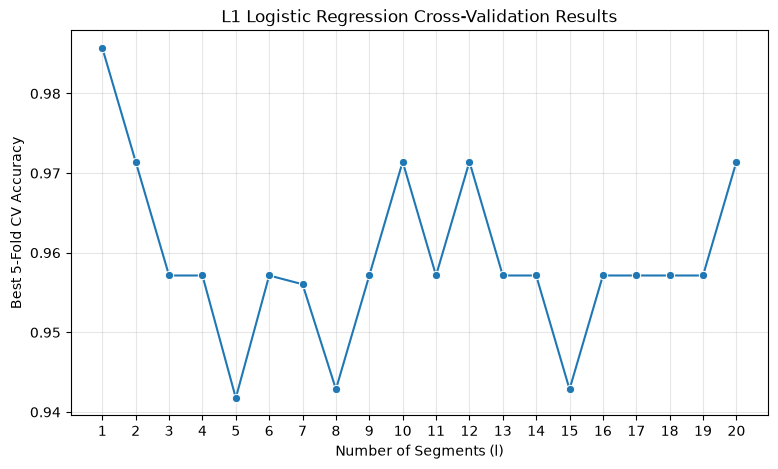

In [65]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=l1_results_df,
    x="l",
    y="CV Accuracy",
    marker="o"
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("Best 5-Fold CV Accuracy")
plt.title("L1 Logistic Regression Cross-Validation Results")
plt.grid(alpha=0.3)

plt.show()

In [66]:
best_l1_feature_names = l1_models[
    best_l_l1
]["feature_names"]

best_l1_coefficients = best_l1_model[
    "logistic"
].coef_[0]

l1_coefficient_table = pd.DataFrame({
    "Feature": best_l1_feature_names,
    "Coefficient": best_l1_coefficients
})

selected_l1_features = l1_coefficient_table[
    l1_coefficient_table["Coefficient"] != 0
].reset_index(drop=True)

print(
    "Number of selected features:",
    len(selected_l1_features)
)

selected_l1_features

Number of selected features: 28


,Feature,Coefficient
0,min1_1,-2.437161
1,max1_1,1.195155
2,mean1_1,-0.537062
3,median1_1,-0.408814
4,std1_1,0.374746
5,third_quartile1_1,-2.944850
6,max2_1,-2.608350
7,median2_1,0.058840
8,third_quartile2_1,-0.312147
9,min3_1,-0.582774


#### ii

In [87]:
best_l1_test_data = create_segmented_feature_dataset(
    test_files,
    num_segments=best_l_l1
)

X_test_l1 = best_l1_test_data.drop(
    columns=["activity", "label"]
)

y_test_l1 = best_l1_test_data["label"]

y_test_l1_pred = best_l1_model.predict(
    X_test_l1
)

l1_test_accuracy = accuracy_score(
    y_test_l1,
    y_test_l1_pred
)

print(
    "L1 cross-validation accuracy:",
    round(best_l1_cv_accuracy, 4)
)

print(
    "L1 test accuracy:",
    round(l1_test_accuracy, 4)
)

L1 cross-validation accuracy: 0.9857
L1 test accuracy: 1.0


In [88]:
model_comparison = pd.DataFrame({
    "Method": [
        "RFE / Variable Selection",
        "L1-Penalized Logistic Regression"
    ],
    "Best l": [
        best_l,
        best_l_l1
    ],
    "CV Accuracy": [
        best_cv_accuracy,
        best_l1_cv_accuracy
    ],
    "Test Accuracy": [
        test_accuracy,
        l1_test_accuracy
    ],
    "Number of Selected Features": [
        best_p,
        len(selected_l1_features)
    ]
})

model_comparison.round(4)

,Method,Best l,CV Accuracy,Test Accuracy,Number of Selected Features
0,RFE / Variable Selection,1,1.0000,0.9474,3
1,L1-Penalized Logistic Regression,1,0.9857,1.0000,28


L1-penalized logistic regression is better and easier to implement

### (c) Multi-class Classification

#### i

In [78]:
multiclass_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

multiclass_results = []
multiclass_models = {}

for l in range(1, 21):
    segmented_data = create_segmented_feature_dataset(
        train_files,
        num_segments=l
    )

    X = segmented_data.drop(
        columns=["activity", "label"]
    )

    y = segmented_data["activity"]

    multinomial_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "logistic",
            LogisticRegression(
                l1_ratio=1,
                solver="saga",
                max_iter=10000,
                random_state=42
            )
        )
    ])

    parameter_grid = {
        "logistic__C": C_values
    }

    grid_search = GridSearchCV(
        estimator=multinomial_pipeline,
        param_grid=parameter_grid,
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X, y)

    best_C_for_l = grid_search.best_params_[
        "logistic__C"
    ]

    best_accuracy_for_l = grid_search.best_score_

    coefficients = grid_search.best_estimator_[
        "logistic"
    ].coef_

    number_nonzero_features = np.sum(
        np.any(coefficients != 0, axis=0)
    )

    multiclass_results.append({
        "l": l,
        "C": best_C_for_l,
        "lambda": 1 / best_C_for_l,
        "Nonzero Features": number_nonzero_features,
        "CV Accuracy": best_accuracy_for_l
    })

    multiclass_models[l] = {
        "model": grid_search.best_estimator_,
        "feature_names": X.columns.tolist()
    }

    print(
        f"l = {l:2d}, "
        f"C = {best_C_for_l:.6f}, "
        f"nonzero features = {number_nonzero_features:3d}, "
        f"CV accuracy = {best_accuracy_for_l:.4f}"
    )

multiclass_results_df = pd.DataFrame(
    multiclass_results
)

multiclass_results_df

l =  1, C = 11.288379, nonzero features =  32, CV accuracy = 0.9134
l =  2, C = 4.281332, nonzero features =  40, CV accuracy = 0.9142
l =  3, C = 78.475997, nonzero features = 124, CV accuracy = 0.8562
l =  4, C = 545.559478, nonzero features = 168, CV accuracy = 0.8693
l =  5, C = 206.913808, nonzero features = 210, CV accuracy = 0.8832
l =  6, C = 206.913808, nonzero features = 252, CV accuracy = 0.8979
l =  7, C = 11.288379, nonzero features = 173, CV accuracy = 0.8538
l =  8, C = 545.559478, nonzero features = 336, CV accuracy = 0.8685
l =  9, C = 29.763514, nonzero features = 305, CV accuracy = 0.8546
l = 10, C = 78.475997, nonzero features = 415, CV accuracy = 0.8391
l = 11, C = 0.615848, nonzero features =  61, CV accuracy = 0.7680
l = 12, C = 78.475997, nonzero features = 502, CV accuracy = 0.8554
l = 13, C = 206.913808, nonzero features = 546, CV accuracy = 0.8407
l = 14, C = 29.763514, nonzero features = 502, CV accuracy = 0.8096
l = 15, C = 206.913808, nonzero features = 63

,l,C,lambda,Nonzero Features,CV Accuracy
0,1,11.288379,0.088587,32,0.913399
1,2,4.281332,0.233572,40,0.914216
2,3,78.475997,0.012743,124,0.856209
3,4,545.559478,0.001833,168,0.869281
4,5,206.913808,0.004833,210,0.883170
5,6,206.913808,0.004833,252,0.897876
6,7,11.288379,0.088587,173,0.853758
7,8,545.559478,0.001833,336,0.868464
8,9,29.763514,0.033598,305,0.854575
9,10,78.475997,0.012743,415,0.839052


In [79]:
best_multiclass_result = multiclass_results_df.loc[
    multiclass_results_df["CV Accuracy"].idxmax()
]

best_l_multiclass = int(
    best_multiclass_result["l"]
)

best_C_multiclass = best_multiclass_result["C"]

best_multiclass_cv_accuracy = best_multiclass_result[
    "CV Accuracy"
]

best_multiclass_model = multiclass_models[
    best_l_multiclass
]["model"]

print("Best l:", best_l_multiclass)
print("Best C:", best_C_multiclass)

print(
    "Best multiclass CV accuracy:",
    round(best_multiclass_cv_accuracy, 4)
)

Best l: 2
Best C: 4.281332398719396
Best multiclass CV accuracy: 0.9142


In [80]:
multiclass_test_data = create_segmented_feature_dataset(
    test_files,
    num_segments=best_l_multiclass
)

X_test_multiclass = multiclass_test_data.drop(
    columns=["activity", "label"]
)

y_test_multiclass = multiclass_test_data["activity"]

y_test_multiclass_pred = best_multiclass_model.predict(
    X_test_multiclass
)

multiclass_test_accuracy = accuracy_score(
    y_test_multiclass,
    y_test_multiclass_pred
)

multiclass_test_error = 1 - multiclass_test_accuracy

print(
    "Multiclass test accuracy:",
    round(multiclass_test_accuracy, 4)
)

print(
    "Multiclass test error:",
    round(multiclass_test_error, 4)
)

Multiclass test accuracy: 0.8421
Multiclass test error: 0.1579


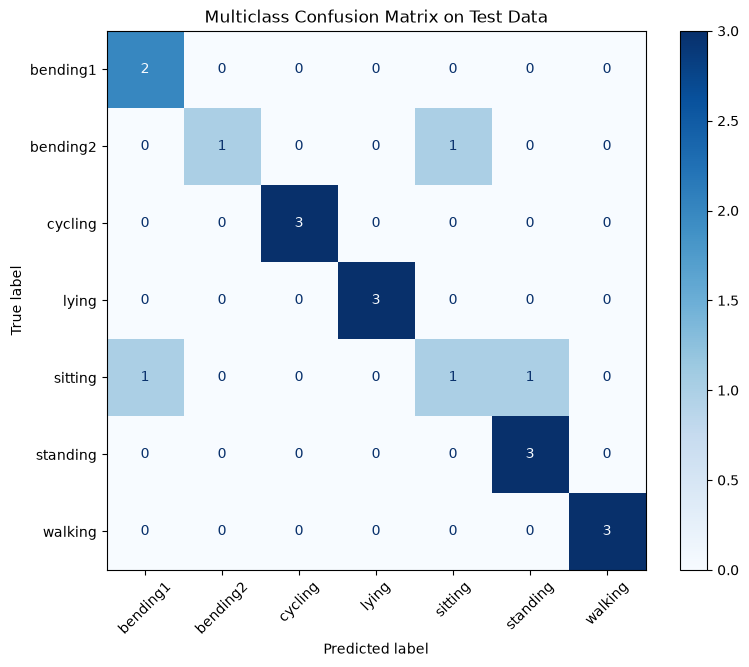

In [81]:
activity_labels = best_multiclass_model[
    "logistic"
].classes_

multiclass_confusion_matrix = confusion_matrix(
    y_test_multiclass,
    y_test_multiclass_pred,
    labels=activity_labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=multiclass_confusion_matrix,
    display_labels=activity_labels
)

fig, ax = plt.subplots(figsize=(9, 7))

display.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Multiclass Confusion Matrix on Test Data")
plt.show()

In [82]:
from sklearn.preprocessing import label_binarize

y_test_probability_multiclass = (
    best_multiclass_model.predict_proba(
        X_test_multiclass
    )
)

y_test_binary = label_binarize(
    y_test_multiclass,
    classes=activity_labels
)

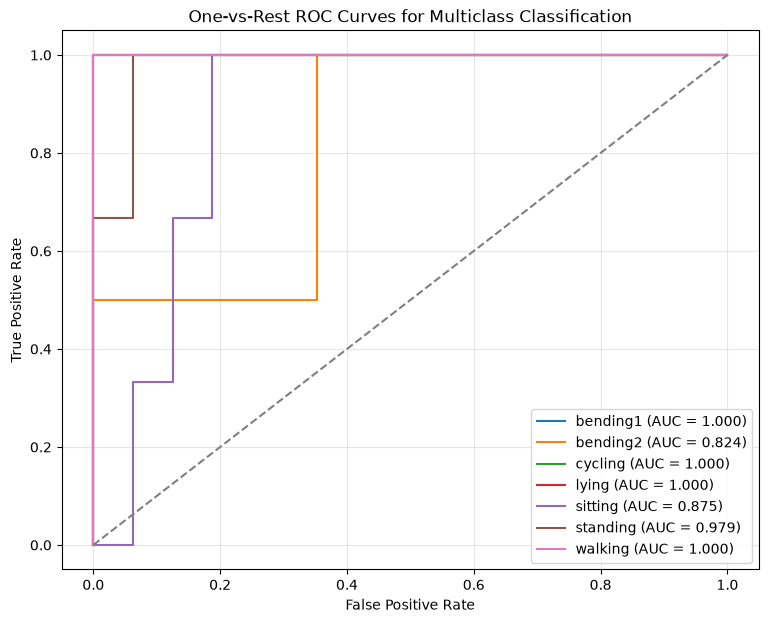

In [83]:
plt.figure(figsize=(9, 7))

class_auc_values = {}

for class_index, activity in enumerate(activity_labels):
    class_fpr, class_tpr, _ = roc_curve(
        y_test_binary[:, class_index],
        y_test_probability_multiclass[:, class_index]
    )

    class_auc = roc_auc_score(
        y_test_binary[:, class_index],
        y_test_probability_multiclass[:, class_index]
    )

    class_auc_values[activity] = class_auc

    plt.plot(
        class_fpr,
        class_tpr,
        label=f"{activity} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves for Multiclass Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [89]:
macro_auc = roc_auc_score(
    y_test_binary,
    y_test_probability_multiclass,
    average="macro",
    multi_class="ovr"
)

print("AUC for each activity:")

for activity, auc_value in class_auc_values.items():
    print(
        f"{activity}: {auc_value:.4f}"
    )

print(
    "Macro-average AUC:",
    round(macro_auc, 4)
)

AUC for each activity:
bending1: 1.0000
bending2: 0.8235
cycling: 1.0000
lying: 1.0000
sitting: 0.8750
standing: 0.9792
walking: 1.0000
Macro-average AUC: 0.954


#### ii

In [90]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler

In [91]:
naive_bayes_results = []

for l in range(1, 21):
    segmented_data = create_segmented_feature_dataset(
        train_files,
        num_segments=l
    )

    X = segmented_data.drop(
        columns=["activity", "label"]
    )

    y = segmented_data["activity"]

    # Gaussian Naive Bayes
    gaussian_model = GaussianNB()

    gaussian_scores = cross_val_score(
        gaussian_model,
        X,
        y,
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    # Multinomial Naive Bayes
    multinomial_model = Pipeline([
        (
            "scaler",
            MinMaxScaler()
        ),
        (
            "naive_bayes",
            MultinomialNB()
        )
    ])

    multinomial_scores = cross_val_score(
        multinomial_model,
        X,
        y,
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    naive_bayes_results.append({
        "l": l,
        "Gaussian CV Accuracy": gaussian_scores.mean(),
        "Multinomial CV Accuracy": multinomial_scores.mean()
    })

    print(
        f"l = {l:2d}, "
        f"Gaussian = {gaussian_scores.mean():.4f}, "
        f"Multinomial = {multinomial_scores.mean():.4f}"
    )

l =  1, Gaussian = 0.8562, Multinomial = 0.7230
l =  2, Gaussian = 0.7966, Multinomial = 0.7672
l =  3, Gaussian = 0.6944, Multinomial = 0.7239
l =  4, Gaussian = 0.6650, Multinomial = 0.6944
l =  5, Gaussian = 0.5637, Multinomial = 0.7672
l =  6, Gaussian = 0.6953, Multinomial = 0.7663
l =  7, Gaussian = 0.6797, Multinomial = 0.7663
l =  8, Gaussian = 0.6936, Multinomial = 0.7377
l =  9, Gaussian = 0.6078, Multinomial = 0.7525
l = 10, Gaussian = 0.6364, Multinomial = 0.7083
l = 11, Gaussian = 0.6503, Multinomial = 0.7083
l = 12, Gaussian = 0.5637, Multinomial = 0.6806
l = 13, Gaussian = 0.5956, Multinomial = 0.7092
l = 14, Gaussian = 0.5515, Multinomial = 0.7230
l = 15, Gaussian = 0.5212, Multinomial = 0.7092
l = 16, Gaussian = 0.5359, Multinomial = 0.7100
l = 17, Gaussian = 0.5523, Multinomial = 0.6797
l = 18, Gaussian = 0.4788, Multinomial = 0.7239
l = 19, Gaussian = 0.4926, Multinomial = 0.6944
l = 20, Gaussian = 0.5376, Multinomial = 0.7092


In [92]:
naive_bayes_results_df = pd.DataFrame(
    naive_bayes_results
)

naive_bayes_results_df

best_gaussian_row = naive_bayes_results_df.loc[
    naive_bayes_results_df[
        "Gaussian CV Accuracy"
    ].idxmax()
]

best_multinomial_row = naive_bayes_results_df.loc[
    naive_bayes_results_df[
        "Multinomial CV Accuracy"
    ].idxmax()
]

best_l_gaussian = int(
    best_gaussian_row["l"]
)

best_l_multinomial = int(
    best_multinomial_row["l"]
)

best_gaussian_cv_accuracy = best_gaussian_row[
    "Gaussian CV Accuracy"
]

best_multinomial_cv_accuracy = best_multinomial_row[
    "Multinomial CV Accuracy"
]

print("Best Gaussian l:", best_l_gaussian)
print(
    "Best Gaussian CV accuracy:",
    round(best_gaussian_cv_accuracy, 4)
)

print("Best Multinomial l:", best_l_multinomial)
print(
    "Best Multinomial CV accuracy:",
    round(best_multinomial_cv_accuracy, 4)
)

Best Gaussian l: 1
Best Gaussian CV accuracy: 0.8562
Best Multinomial l: 2
Best Multinomial CV accuracy: 0.7672


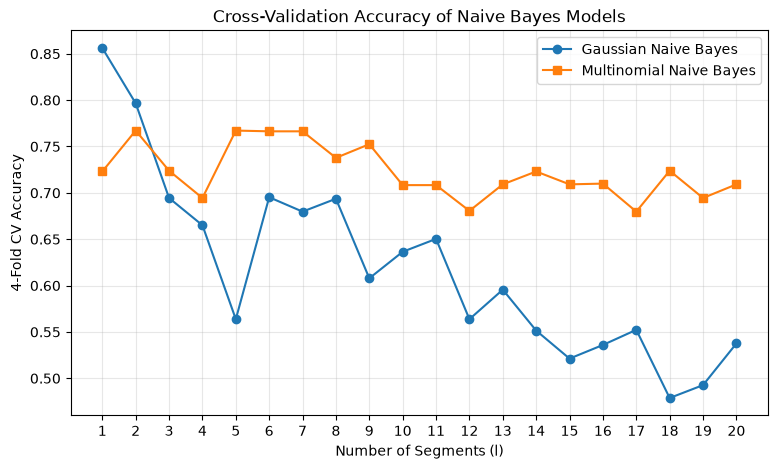

In [93]:
plt.figure(figsize=(9, 5))

plt.plot(
    naive_bayes_results_df["l"],
    naive_bayes_results_df["Gaussian CV Accuracy"],
    marker="o",
    label="Gaussian Naive Bayes"
)

plt.plot(
    naive_bayes_results_df["l"],
    naive_bayes_results_df["Multinomial CV Accuracy"],
    marker="s",
    label="Multinomial Naive Bayes"
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("4-Fold CV Accuracy")
plt.title("Cross-Validation Accuracy of Naive Bayes Models")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [94]:
gaussian_train_data = create_segmented_feature_dataset(
    train_files,
    num_segments=best_l_gaussian
)

gaussian_test_data = create_segmented_feature_dataset(
    test_files,
    num_segments=best_l_gaussian
)

X_train_gaussian = gaussian_train_data.drop(
    columns=["activity", "label"]
)

y_train_gaussian = gaussian_train_data["activity"]

X_test_gaussian = gaussian_test_data.drop(
    columns=["activity", "label"]
)

y_test_gaussian = gaussian_test_data["activity"]

best_gaussian_model = GaussianNB()

best_gaussian_model.fit(
    X_train_gaussian,
    y_train_gaussian
)

gaussian_test_prediction = best_gaussian_model.predict(
    X_test_gaussian
)

gaussian_test_probability = best_gaussian_model.predict_proba(
    X_test_gaussian
)

gaussian_test_accuracy = accuracy_score(
    y_test_gaussian,
    gaussian_test_prediction
)

gaussian_test_error = 1 - gaussian_test_accuracy

In [95]:
multinomial_train_data = create_segmented_feature_dataset(
    train_files,
    num_segments=best_l_multinomial
)

multinomial_test_data = create_segmented_feature_dataset(
    test_files,
    num_segments=best_l_multinomial
)

X_train_multinomial = multinomial_train_data.drop(
    columns=["activity", "label"]
)

y_train_multinomial = multinomial_train_data["activity"]

X_test_multinomial = multinomial_test_data.drop(
    columns=["activity", "label"]
)

y_test_multinomial = multinomial_test_data["activity"]

best_multinomial_model = Pipeline([
    (
        "scaler",
        MinMaxScaler()
    ),
    (
        "naive_bayes",
        MultinomialNB()
    )
])

best_multinomial_model.fit(
    X_train_multinomial,
    y_train_multinomial
)

multinomial_test_prediction = best_multinomial_model.predict(
    X_test_multinomial
)

multinomial_test_probability = (
    best_multinomial_model.predict_proba(
        X_test_multinomial
    )
)

multinomial_test_accuracy = accuracy_score(
    y_test_multinomial,
    multinomial_test_prediction
)

multinomial_test_error = 1 - multinomial_test_accuracy

In [96]:
naive_bayes_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        best_l_gaussian,
        best_l_multinomial
    ],
    "CV Accuracy": [
        best_gaussian_cv_accuracy,
        best_multinomial_cv_accuracy
    ],
    "Test Accuracy": [
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "Test Error": [
        gaussian_test_error,
        multinomial_test_error
    ]
})

naive_bayes_comparison.round(4)

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,Gaussian Naive Bayes,1,0.8562,0.8947,0.1053
1,Multinomial Naive Bayes,2,0.7672,0.7895,0.2105


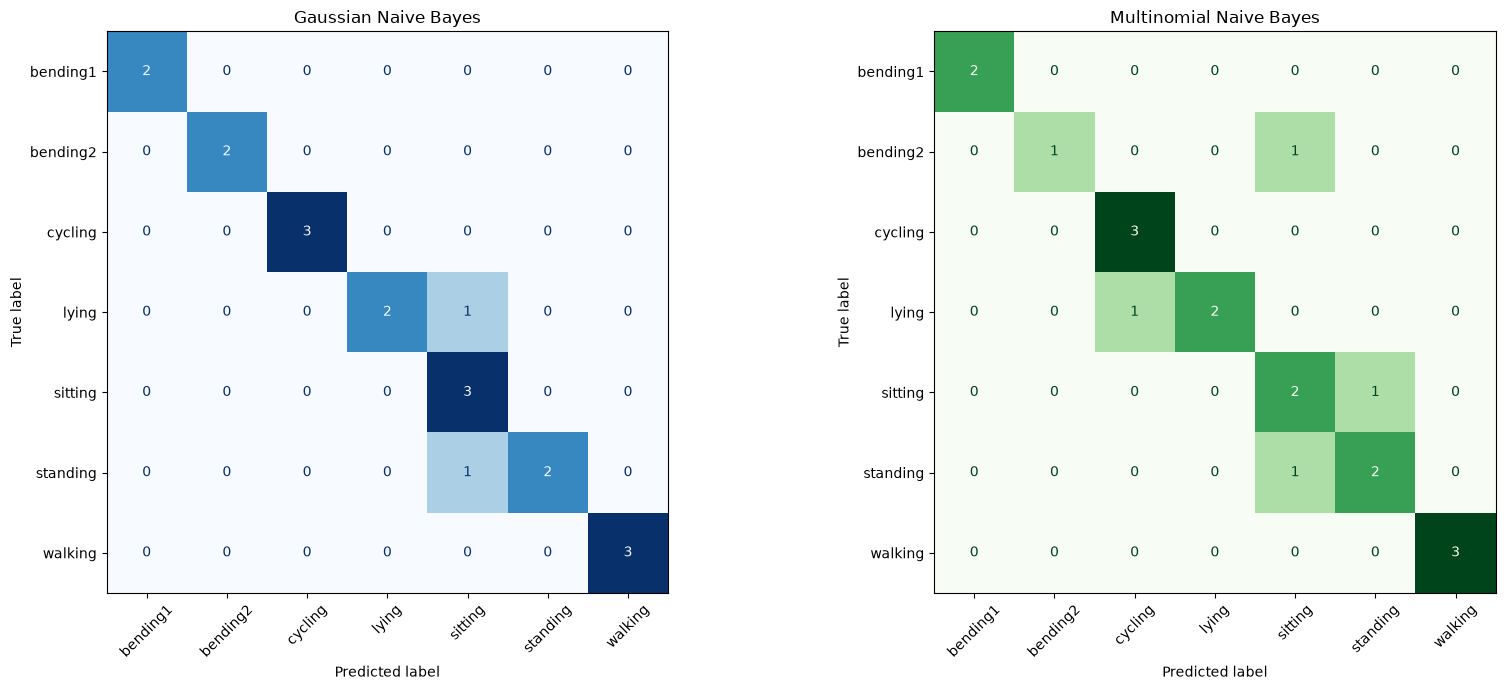

In [97]:
gaussian_classes = best_gaussian_model.classes_

multinomial_classes = best_multinomial_model[
    "naive_bayes"
].classes_

gaussian_confusion = confusion_matrix(
    y_test_gaussian,
    gaussian_test_prediction,
    labels=gaussian_classes
)

multinomial_confusion = confusion_matrix(
    y_test_multinomial,
    multinomial_test_prediction,
    labels=multinomial_classes
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7)
)

ConfusionMatrixDisplay(
    gaussian_confusion,
    display_labels=gaussian_classes
).plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Gaussian Naive Bayes")

ConfusionMatrixDisplay(
    multinomial_confusion,
    display_labels=multinomial_classes
).plot(
    cmap="Greens",
    xticks_rotation=45,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Multinomial Naive Bayes")

plt.tight_layout()
plt.show()

#### iii

In [98]:
multiclass_model_comparison = pd.DataFrame({
    "Model": [
        "L1 Multinomial Logistic Regression",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        best_l_multiclass,
        best_l_gaussian,
        best_l_multinomial
    ],
    "CV Accuracy": [
        best_multiclass_cv_accuracy,
        best_gaussian_cv_accuracy,
        best_multinomial_cv_accuracy
    ],
    "Test Accuracy": [
        multiclass_test_accuracy,
        gaussian_test_accuracy,
        multinomial_test_accuracy
    ],
    "Test Error": [
        multiclass_test_error,
        gaussian_test_error,
        multinomial_test_error
    ]
})

multiclass_model_comparison.round(4)

,Model,Best l,CV Accuracy,Test Accuracy,Test Error
0,L1 Multinomial Logistic Regression,2,0.9142,0.8421,0.1579
1,Gaussian Naive Bayes,1,0.8562,0.8947,0.1053
2,Multinomial Naive Bayes,2,0.7672,0.7895,0.2105


In [99]:
best_model_row = multiclass_model_comparison.loc[
    multiclass_model_comparison[
        "Test Error"
    ].idxmin()
]

print(
    "Best multiclass model:",
    best_model_row["Model"]
)

print(
    "Best test accuracy:",
    round(best_model_row["Test Accuracy"], 4)
)

print(
    "Lowest test error:",
    round(best_model_row["Test Error"], 4)
)

Best multiclass model: Gaussian Naive Bayes
Best test accuracy: 0.8947
Lowest test error: 0.1053


## 3. ISLR 4.8.3

In the normal distribution formula, the term

$$(x-\mu_k)^2$$

produces an \(x^2\) term when expanded:

$$(x-\mu_k)^2=x^2-2\mu_kx+\mu_k^2.$$

If all classes have the same variance, their \(x^2\) terms have the same
coefficient and cancel when the class discriminant functions are compared,
resulting in a linear decision boundary. However, QDA allows different classes
to have different variances:

$$\sigma_1^2 \neq \sigma_2^2.$$

Therefore, the coefficients of the \(x^2\) terms are different and cannot
cancel. The decision boundary still contains an \(x^2\) term, so it is
quadratic rather than linear.

## 4. ISLR 4.8.7

$$
\mu_{\text{Yes}}=10,\qquad
\mu_{\text{No}}=0,\qquad
\sigma^2=36,
$$

The prior probabilities are

$$
P(\text{Yes})=0.8,\qquad
P(\text{No})=0.2.
$$

Bayes' theorem

$$
P(\text{Yes}\mid X=4)
=
\frac{P(\text{Yes})f_{\text{Yes}}(4)}
{P(\text{Yes})f_{\text{Yes}}(4)
+P(\text{No})f_{\text{No}}(4)}.
$$

The two classes have the same variance

$$
P(\text{Yes}\mid X=4)
=
\frac{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
}{
0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
+
0.2\exp\left(-\frac{(4-0)^2}{2(36)}\right)
}.
$$

$$
P(\text{Yes}\mid X=4)
\approx 0.752.
$$

Therefore, the probability that the company will issue a dividend this year is
approximately \(75.2\%\).